In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation

In [2]:
def masked_mse(arr1, arr2, inner_start=5, inner_end=27):
    """
    Вычисляет MSE между двумя массивами, игнорируя внутреннюю часть [inner_start:inner_end, inner_start:inner_end].
    
    Параметры:
    ----------
    arr1, arr2 : numpy.ndarray
        Двумерные массивы одинакового размера.
    inner_start, inner_end : int
        Границы внутренней области, которую нужно исключить из расчёта.
        
    Возвращает:
    -----------
    mse : float
        Среднеквадратичная ошибка (без учета внутренней части).
    """
    # Создаём маску: True там, где элементы ДОЛЖНЫ учитываться в MSE (вне внутренней части)
    mask = np.ones_like(arr1, dtype=bool)
    mask[inner_start:inner_end, inner_start:inner_end] = False
    
    # Применяем маску к обоим массивам
    masked_arr1 = arr1[mask]
    masked_arr2 = arr2[mask]
    
    # Вычисляем MSE только по валидным элементам
    squared_errors = (masked_arr1 - masked_arr2) ** 2
    mse = np.mean(squared_errors)
    
    return mse

Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.021886821940635518
  u_yy: 0.1527815598649837
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 7.111545531786972
  u_yy: 10.336541664738071
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 28.91836971353264
  u_yy: 19.630590849813995


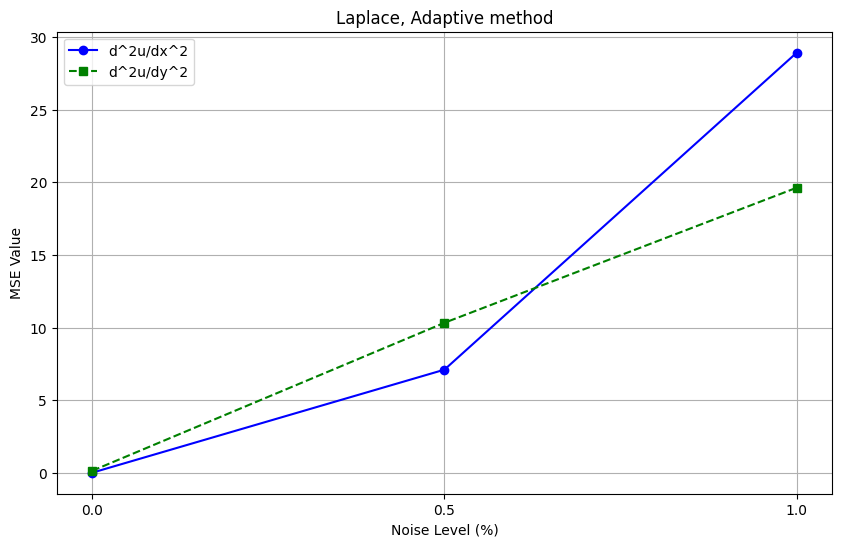

In [3]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Adaptive_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Adaptive_yy_noise{noise}.npy')

    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_yy = masked_mse(u_yy, gradient_yy, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.009295271507315187
  u_yy: 0.005161187276380391
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 72.4687954334269
  u_yy: 79.11332785855133
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 238.29982104310128
  u_yy: 231.4645344791169


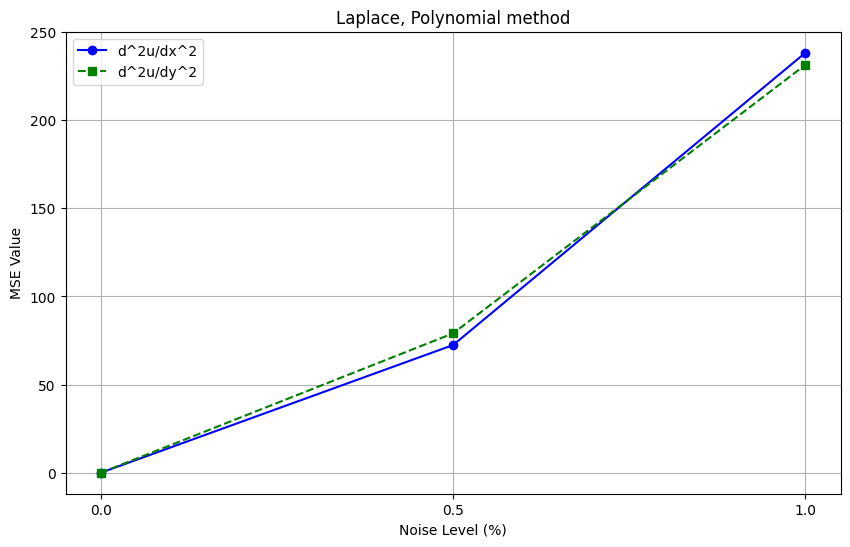

In [4]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Polynomial_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Polynomial_yy_noise{noise}.npy')

        
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_yy = masked_mse(u_yy, gradient_yy, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 265.66240808737007
  u_yy: 153.8350100798475
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 287.4326263761016
  u_yy: 190.307344761447
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 351.056484342283
  u_yy: 219.64776696935354


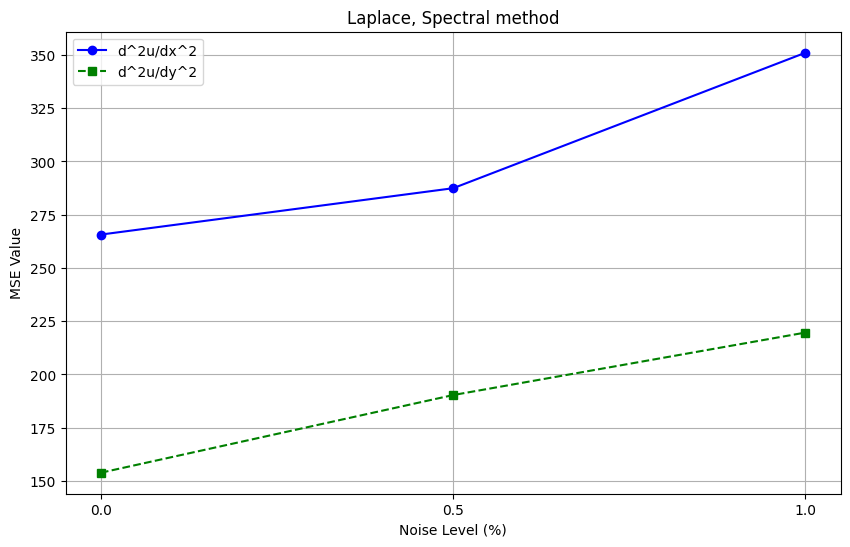

In [5]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Spectral_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Spectral_yy_noise{noise}.npy')
    
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_yy = masked_mse(u_yy, gradient_yy, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.01699154707879656
  u_yy: 0.3304578899431683
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 5887.061975964669
  u_yy: 806.034418558293
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 8770.915594545479
  u_yy: 178600.1116384846


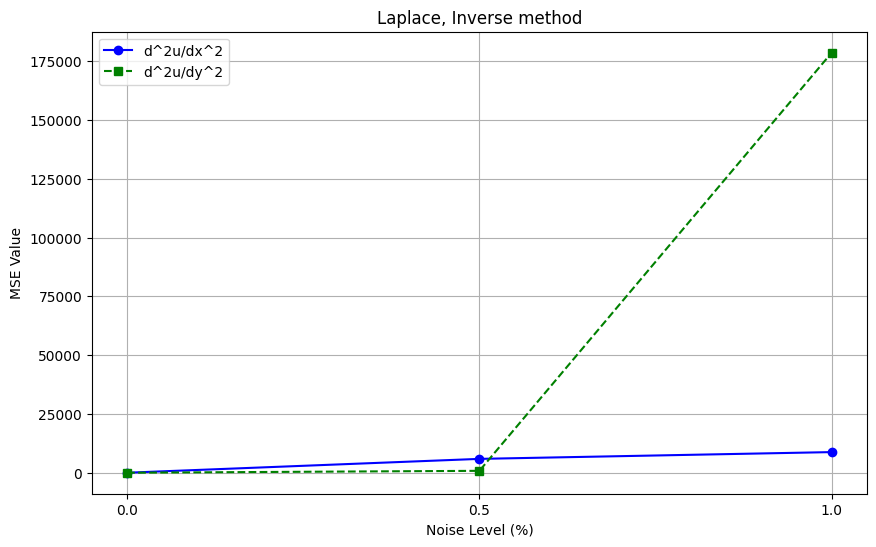

In [7]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Inverse_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Inverse_yy_noise{noise}.npy')
    
    
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_yy = masked_mse(u_yy, gradient_yy, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 1.6339244892733396
  u_yy: 1.4325245308138732
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 21.035713686645924
  u_yy: 27.203677478056385
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 83.67292735461379
  u_yy: 57.06574971169442


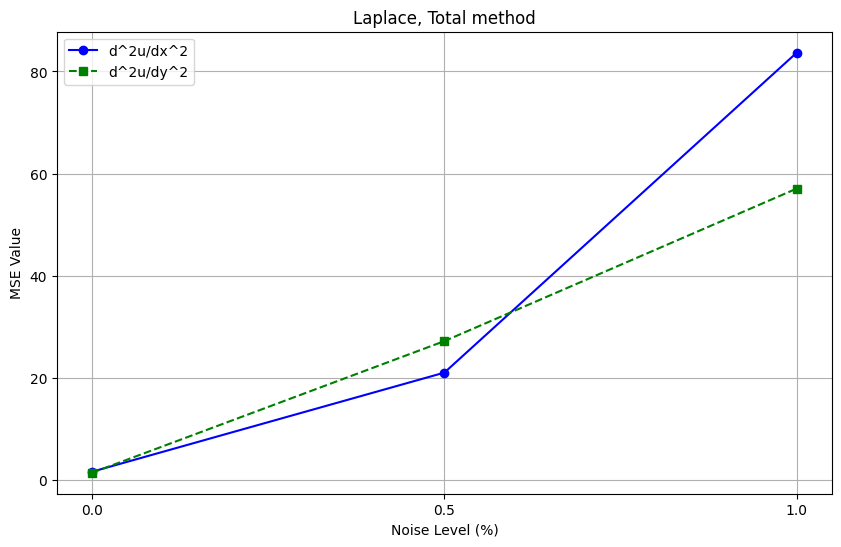

In [8]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_yy = []

for noise in noise_levels:
    u_xx = np.load(f'Laplace_Gradient_xx_noise{noise}.npy')
    u_yy = np.load(f'Laplace_Gradient_yy_noise{noise}.npy')
    
    gradient_xx = np.load(f'Laplace_Total_xx_noise{noise}.npy')
    gradient_yy = np.load(f'Laplace_Total_yy_noise{noise}.npy')

       
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_yy = masked_mse(u_yy, gradient_yy, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_yy.append(mse_u_yy)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_yy: {mse_u_yy}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_yy, marker='s', linestyle='--', color='g', label='d^2u/dy^2')

plt.title('Laplace, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Laplace_Total_error.pdf', format='pdf')
plt.show()


In [10]:
u_xx

array([[ -1.07014462,   9.78872951,  18.35416469,  24.53138987],
       [  8.40013259,   9.45255668,  -9.82166342, -34.85341683],
       [ -6.40247096,  -3.3083735 ,  29.55643371,  59.07399526],
       [ -4.94780092,  -1.58865347,   8.8841008 ,  15.50202474]])